# Linear Regression from Scratch: Salary vs Years of Experience

**Author:** Benedicta Bondzie, known as The Tech Diva
**LinkedIn:** [https://www.linkedin.com/in/benedicta-bondzie-the-tech-diva/](https://www.linkedin.com/in/benedicta-bondzie-the-tech-diva/)

---

## What this notebook is

This notebook builds **simple linear regression from scratch**. Every calculation that makes the model, which means the slope, the intercept, the predictions and the evaluation metrics, is written by hand using plain Python and NumPy. There is no `sklearn`, there are no classes, and there are no ready-made `.fit()` or `.predict()` methods.

It is written so that a beginner can read it from top to bottom, understand the maths behind linear regression, and then rebuild it themselves.

## The rules I set for this project

| Tool | What I allowed it to do |
|---|---|
| **NumPy** | All of the maths: sums, means, slope, intercept, predictions, metrics |
| **pandas** | Load the CSV, inspect it and clean it. Nothing else |
| **matplotlib and seaborn** | Draw charts only. They never calculate anything for the model |
| **scikit-learn** | Not used at all |
| **Classes and objects** | Not used. Everything is plain functions |

## The data

The data is a **synthetic** (made-up) dataset of 100 people: years of experience and salary. I made it to look like a real salary dataset, with salary rising as experience rises, plus some natural scatter. It deliberately contains **missing values**, so that cleaning the data is part of the project. A second, complete copy of the same data is used only to check that my functions are correct.

Because the data is synthetic, the results show that the method works. They are **not** real facts about salaries in any country.

## Files you need

Put these two files in the same folder as this notebook (in Google Colab, upload them using the Files panel on the left):

- `Salary_Data_100_messy.csv` (the data with missing values, used for the model)
- `Salary_Data_100_clean.csv` (the complete copy, used only to check my functions)

## Roadmap

1. Setup
2. Load the data
3. Inspect the data
4. Clean the data
5. Move to NumPy and look at the data
6. Split into training and testing sets (by hand)
7. Check the ranges of the two sets
8. Write the functions (`fit`, `predict`, five metrics, `residuals`, `correlation`)
9. Check that the functions are correct
10. Train the model (find the slope and intercept)
11. Predict
12. Visualise the regression line
13. Evaluate the model
14. Look at the residuals
15. Check the assumptions
16. The story: what I found
17. What I would do next

---
# Step 1: Setup

Four libraries are imported, and each has a limited job:

- `numpy` does all of the maths.
- `pandas` loads, inspects and cleans the table.
- `matplotlib.pyplot` draws charts.
- `seaborn` draws a few charts in a cleaner style.

None of these four libraries builds the regression model. That part is written by hand in the steps that follow.

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
# Step 2: Load the data

`pd.read_csv` reads the file into a table called a DataFrame, which we name `df`. `df.head(10)` shows the first 10 rows, so we can see what we are working with.

Look at the `NaN` values in the output. `NaN` means "not a number", which is how pandas shows a blank cell. This file has missing values on purpose.

In [101]:
df = pd.read_csv("Salary_Data_100_messy.csv")
df.head(10)

,YearsExperience,Salary
0,9.30000000,"112,772.00000000"
1,10.10000000,NaN
2,0.70000000,"29,736.00000000"
3,7.70000000,"88,338.00000000"
4,NaN,"118,816.00000000"
5,NaN,"120,020.00000000"
6,13.60000000,"137,836.00000000"
7,5.90000000,"78,385.00000000"
8,NaN,"107,106.00000000"
9,7.70000000,"107,681.00000000"


---
# Step 3: Inspect the data

Before touching the data, I look at it from four angles:

1. `df.dtypes` shows the data type of each column. We want numbers (`float64`), not text.
2. `df.describe()` shows count, mean, spread, minimum and maximum for each column.
3. `df.info()` shows how many non-empty values each column has.
4. `df.isnull().sum()` counts the missing values in each column.

**What to notice:** there are 100 rows, but `count` and `Non-Null Count` show only **94** for each column. So **6 values are missing in YearsExperience and 6 are missing in Salary**.

In [102]:
print(df.dtypes)

YearsExperience    float64
Salary             float64
dtype: object


In [103]:
df.describe()

,YearsExperience,Salary
count,94.00000000,94.00000000
mean,7.94893617,"100,580.85106383"
std,3.83233960,"35,851.71068457"
min,0.50000000,"25,342.00000000"
25%,5.10000000,"76,909.50000000"
50%,8.00000000,"99,289.50000000"
75%,10.52500000,"127,020.50000000"
max,14.90000000,"165,275.00000000"


In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  94 non-null     float64
 1   Salary           94 non-null     float64
dtypes: float64(2)
memory usage: 1.7 KB


In [105]:
df.isnull().sum()

,0
YearsExperience,6
Salary,6


---
# Step 4: Clean the data

Linear regression cannot work with blank values, so each of the 12 missing values has to be dealt with. There are two common choices:

- **Fill** the blank with something, for example the column mean.
- **Drop** the whole row that has a blank.

**My choice: drop the rows.**

### What went wrong the first time

My first attempt was to fill the blanks with the column mean. The model looked fine on the training set but much worse on the test set:

| Run (earlier, mean fill) | Training | Testing |
|---|---|---|
| R-squared | 0.905 | 0.774 |
| RMSE | about 10,700 | about 16,000 |

I first suspected the split, because a sorted file can put only high-experience people in the test set. But the file was shuffled. The test range was also inside the training range (this is checked again in Step 7), so it was not an extrapolation problem either.

Then I looked at the **largest test residual**. It belonged to a row whose experience had been filled in with the mean (7.9 years), while the real salary was 155,087, a salary that belongs to someone with about 15 years of experience. The model's error on that one row was about 55,000. Errors are squared in MSE, so that one invented point produced more than half of the whole test MSE. The test set only had about 20 rows, so a single bad row had a huge effect.

**The lesson:** filling a blank with the mean puts a made-up point into the data. In a regression, that point can sit far from the real line and distort both the fit and the evaluation. When only a small number of rows are affected, dropping them is safer.

The mean-fill experiment is not in the code below, so this table is from my earlier run. The final results, with the rows dropped, are in Step 13.

### The cleaning step

`df.dropna()` removes every row that has a blank in any column. The result must be saved back into `df`, because `dropna` returns a new table instead of changing the old one. I print the row counts before and after, so the loss is visible, and then check the data types and the missing values again.

In [106]:
rows_before = len(df)

df = df.dropna()

rows_after = len(df)
print("Rows before dropping:", rows_before)
print("Rows after dropping: ", rows_after)
print("Rows removed:        ", rows_before - rows_after)
print()

#Checking data type so see if pandas has not mistankenly chosen a datatype for me

print(df["YearsExperience"].dtype)
print(df["Salary"].dtype)

print()

#Checking to see missing values again
print("Checking missing values again: \n")
print(df.isnull().sum())

Rows before dropping: 100
Rows after dropping:  88
Rows removed:         12

float64
float64

Checking missing values again: 

YearsExperience    0
Salary             0
dtype: int64


In [107]:
# Confirm the column names
df.columns.tolist()

['YearsExperience', 'Salary']

---
# Step 5: Move to NumPy and look at the data

From this point on, the model is built with NumPy. `.to_numpy()` turns each pandas column into a plain NumPy array.

Why switch? There are two reasons.

1. **It keeps the project honest.** Once the data is in NumPy, every calculation I write is clearly mine and not something pandas did behind the scenes.
2. **It avoids a pandas trap.** Pandas matches rows by their index labels when it combines columns. After rows are dropped, the labels have gaps, and combining columns from different parts of a table can quietly give wrong answers. NumPy arrays only care about position.

Naming the arrays:

- `x` is the **feature**, the input we know: `YearsExperience`.
- `y` is the **target**, the output we want to predict: `Salary`.

After that I draw the whole cleaned dataset as a scatter plot. This is the first look at the relationship: does salary rise in something close to a straight line as experience rises?

In [108]:
#Move to NumPy

x = df["YearsExperience"].to_numpy()
y = df["Salary"].to_numpy()

# data = np.column_stack((x, y))
# print("YearsExperience  Salary")
# print(data)

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (88,)
y shape: (88,)


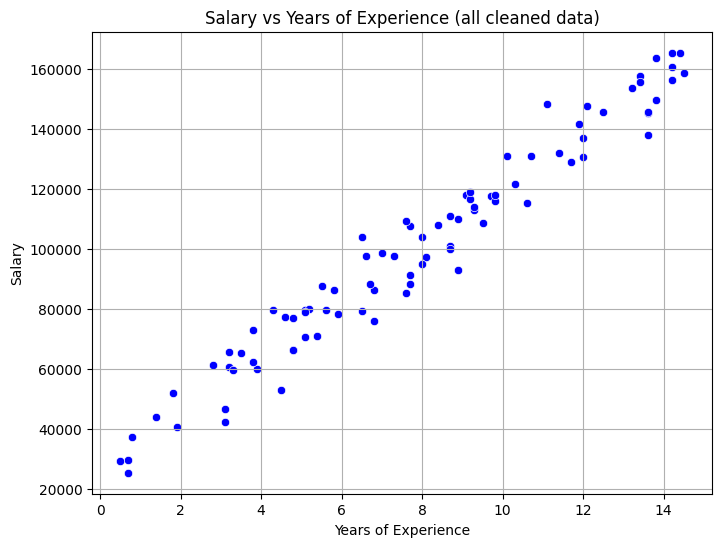

In [109]:
# A first look at the whole cleaned dataset
plt.figure(figsize=(8,6))
sns.scatterplot(x=x, y=y, color='blue')
plt.title('Salary vs Years of Experience (all cleaned data)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.grid(True)
plt.show()

**What the chart shows:** the points rise from the bottom left to the top right in a rough straight band. That is the pattern a straight line can capture, so linear regression is a reasonable model to try.

---
# Step 6: Split into training and testing sets (by hand)

A model should be judged on data it has never seen. So the data is split in two:

- The **training set** is used to learn the slope and the intercept.
- The **testing set** is held back and used only to see how well the learned line works on new rows.

### The rule: roughly 80% train, 20% test

`df.shape` shows how many rows are left after cleaning. In my run it is **88**. Then:

88 rows x 0.8 = 70.4, and you cannot have 0.4 of a row, so I use **70 rows for training** and the remaining **18 rows for testing**. That is 79.5% and 20.5%, which is as close to 80/20 as 88 rows allows.

### How the slicing works

`df.iloc[rows, column]` picks by **position**. Rows start counting at 0, and the end number of a slice is left out:

- `0:70` means positions 0 to 69, which is 70 rows (the training rows)
- `70:` means position 70 to the end, which is the last 18 rows (the testing rows)
- column `0` is `YearsExperience` and column `1` is `Salary`

### Why no shuffling is needed here

The rows in this file are already in a mixed order, so the last 18 rows are a fair sample. If a file were sorted from low to high experience, taking the last rows would give a test set with only very experienced people, and the model would be tested on a range it never saw. Always check the file's order before slicing.

### Two rules for the split

1. The **same row numbers** must be used for x and y, or the experience values would be matched with the wrong salaries.
2. The numbers 70 and 18 are tied to this particular cleaned table. If the cleaning changes and a different number of rows is left, the cut position has to be worked out again.

### Why check the type and the shape?

The two prints at the end of the cell are a safety check:

- The **type** must be `numpy.ndarray`. This proves the data is really in NumPy and not still a pandas column.
- The **shape** must be `(70,)`, `(18,)`, `(70,)` and `(18,)`. A shape like `(70,)` means "one dimension with 70 values". This proves that x and y have the same length in each set. If one of them were `(70, 1)` and the other `(70,)`, NumPy would silently combine them into a 70 by 70 grid and every sum would be wrong, with no error message.

In [110]:
#Checking to see shape of dataframe so i can split is easily

df.shape

(88, 2)

In [111]:
#Splitting data: 88 rows x 0.8 = 70.4, so 70 rows for training and the last 18 rows for testing
print(len(df))
print()
x_train = df.iloc[0:70, 0].to_numpy()
x_test = df.iloc[70:, 0].to_numpy()
y_train = df.iloc[0:70, 1].to_numpy()
y_test = df.iloc[70:, 1].to_numpy()

print("Data Type of X_train:", type(x_train))
print("Data Type of X_test:", type(x_test))
print("Data Type of y_train:", type(y_train))
print("Data Type of y_test:", type(y_test))
print()

print("Shape of testing and training data: ")
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

88

Data Type of X_train: <class 'numpy.ndarray'>
Data Type of X_test: <class 'numpy.ndarray'>
Data Type of y_train: <class 'numpy.ndarray'>
Data Type of y_test: <class 'numpy.ndarray'>

Shape of testing and training data: 
(70,)
(18,)
(70,)
(18,)


---
# Step 7: Check the ranges of the two sets

A straight-line model is only trustworthy **inside the range of data it learned from**. If the test set contained experience values far outside the training range, the model would be guessing, and a poor test score would not be the model's fault.

So before fitting anything, I compare the smallest and largest experience in each set.

In [112]:
# seeing the range of values to understand what is going on
print("Training experience range:")
print(f"{x_train.min()} - {x_train.max()}")

print("Testing experience range:")
print(f"{x_test.min()} - {x_test.max()}")

Training experience range:
0.5 - 14.5
Testing experience range:
2.8 - 12.5


**Result:** training covers 0.5 to 14.5 years, and testing covers 2.8 to 12.5 years. The testing range sits **completely inside** the training range, so the model will not be asked to predict outside what it has seen.

---
# Step 8: Write the functions

Now I write the tools I need. Each one is a function: a small recipe that takes inputs and returns an answer.

A function is **written once and used many times**. The names inside the brackets, like `x` and `y` in `fit(x, y)`, are only placeholders for "whatever data I hand you". When the function is used, I decide what goes in. For example, `predict` will be called once with the training data and once with the testing data.

At this point I only **define** the functions. Nothing is calculated yet. Here are the nine functions:

1. `fit` learns the slope and the intercept
2. `predict` uses them to make predictions
3. `mse`, 4. `mae`, 5. `rmse`, 6. `r2` and 7. `adjusted_r2` measure how good the predictions are
8. `residuals` gives the errors
9. `correlation` measures how straight-line the relationship is

### Function 1: `fit(x, y)`

**What it does:** finds the best-fit line using the **least squares** sum formulas. This is the learning step of the whole project.

**Takes in:** `x` (the feature array) and `y` (the target array), both the same length.

**Returns:** two numbers, `m` (the slope) and `b` (the intercept).

The formulas, with $n$ as the number of rows:

$$m = \frac{n\sum xy - \sum x \sum y}{n\sum x^2 - \left(\sum x\right)^2}$$

$$b = \frac{\sum y - m\sum x}{n}$$

**Be careful with two similar-looking quantities:**

- $\sum x^2$ means square each x first, then add them up. In code: `(x**2).sum()`
- $\left(\sum x\right)^2$ means add the x values up first, then square the total. In code: `x.sum() ** 2`

They give different numbers, and mixing them up is the most common mistake.

The code builds the top and the bottom of the slope fraction separately, and then divides, so each line is small and easy to check.

I explained how to calculate the slope and the intercept step by step in a LinkedIn post. You can read it here: [Benedicta on LinkedIn](https://www.linkedin.com/in/benedicta-bondzie-the-tech-diva/)
<!-- Replace the link above with the direct link to the LinkedIn post if you want it to open the post itself -->

In [113]:
#Writing Functions for the calculations

# Calculating the slope and intercept

def fit(x, y):

  n = len(x)
  sumXY = (x*y).sum()
  sumX = x.sum()
  sumY = y.sum()
  sumX2 = (x**2).sum()
  sumX_squared = sumX ** 2

  upper  = (n * sumXY) - (sumX * sumY)
  down = (n * sumX2 - sumX_squared)

  # Calculating slope

  m = upper / down

  # Calculating intercept
  upper1 = (sumY) - (m * sumX)
  down1 = (n)
  b = upper1 / down1

  return m, b

### Function 2: `predict(x, m, b)`

**What it does:** puts x values into the line $\hat{y} = mx + b$ and returns the predicted salary for each one.

**Takes in:** an array of x values, plus the slope `m` and the intercept `b`.

**Returns:** an array of predicted y values, one for each x.

NumPy applies `m * x + b` to the whole array in one go, so no loop is needed.

In [114]:
def predict(x, m, b):
  y_pred = m * x + b
  return y_pred

### Function 3: `mse(actual, pred)`, Mean Squared Error

**What it does:** subtracts each prediction from the real value, squares each difference, and takes the average.

**Takes in:** an array of actual values and an array of predicted values.

**Returns:** one number.

$$MSE = \frac{1}{n}\sum \left(y_i - \hat{y}_i\right)^2$$

Squaring does two things: it stops positive and negative errors from cancelling out, and it punishes large mistakes much more than small ones. The unit is salary squared, so the number is large and hard to picture. That is why RMSE exists.

In [115]:
def mse(actual, pred):
  MSE = np.square(np.subtract(actual, pred)).mean()
  return MSE

### Function 4: `mae(actual, pred)`, Mean Absolute Error

**What it does:** takes the size of each error (ignoring whether it is positive or negative) and averages them.

**Takes in:** actual values and predicted values.

**Returns:** one number, in the same unit as salary.

$$MAE = \frac{1}{n}\sum \left|y_i - \hat{y}_i\right|$$

This one is the easiest to explain in words: "on average, the prediction is off by this much."

In [116]:
def mae(actual, pred):
  MAE = np.absolute(np.subtract(actual, pred)).mean()
  return MAE

### Function 5: `rmse(actual, pred)`, Root Mean Squared Error

**What it does:** takes the MSE and then the square root, which brings the error back into salary units.

**Takes in:** actual values and predicted values.

**Returns:** one number, in the same unit as salary.

$$RMSE = \sqrt{MSE}$$

RMSE is a "typical error" size, but because it comes from squared errors, it gives more weight to large mistakes than MAE does. When RMSE is much bigger than MAE, it is a sign that a few predictions are badly wrong.

In [117]:
def rmse(actual, pred):
  rmse = np.square(np.subtract(actual, pred)).mean()
  RMSE = np.sqrt(rmse)
  return RMSE

### Function 6: `r2(actual, pred)`, R-squared

**What it does:** measures what share of the ups and downs in salary the model explains.

**Takes in:** actual values and predicted values.

**Returns:** one number. 1 is a perfect fit, 0 means the model is no better than always guessing the average salary, and it can even go below 0 if the model is worse than that.

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$

- $SS_{res} = \sum (y_i - \hat{y}_i)^2$ is the error left over after using the model (`res` in the code)
- $SS_{tot} = \sum (y_i - \bar{y})^2$ is the total variation in the actual values around their own average (`tss` in the code)

In [118]:
def r2(actual, pred):

  res = np.sum((actual - pred) ** 2)
  tss = np.sum((actual - actual.mean()) ** 2)

  RSQUARED = 1 - (res/tss)
  return RSQUARED

### Function 7: `adjusted_r2(actual, pred, k)`, Adjusted R-squared

**What it does:** corrects R-squared for the number of features used. Plain R-squared never goes down when you add another feature, even a useless one. Adjusted R-squared adds a penalty for every extra feature, so it only improves when a new feature really helps.

**Takes in:** actual values, predicted values, and `k`, the number of features. Here `k` is **1**, because we use only YearsExperience.

**Returns:** one number.

$$R^2_{adj} = 1 - \left(1 - R^2\right)\frac{n-1}{n-k-1}$$

**What to expect:** with just one feature, adjusted R-squared will be very close to R-squared. It becomes useful later, with multiple linear regression, where it helps to decide whether a new feature earns its place.

In [119]:
def adjusted_r2(actual, pred, k):
    n = len(actual)
    method1 = 1 - r2(actual, pred)
    method2 = (n - 1) / (n - k - 1)
    adj_r2 = 1 - (method1 * method2)
    return adj_r2

### Function 8: `residuals(actual, pred)`

**What it does:** returns the error for each row: the actual value minus the predicted value.

**Takes in:** actual values and predicted values.

**Returns:** an array of errors, one per row.

- A **positive** residual means the model predicted too low.
- A **negative** residual means the model predicted too high.

The assumption checks in Step 15 all work from the residuals.

In [120]:
def residuals (actual, pred):
  return (actual - pred)

### Function 9: `correlation(x, y)`

**What it does:** measures how closely x and y follow a straight line.

**Takes in:** the x array and the y array.

**Returns:** one number $r$ between -1 and +1. Close to +1 means a strong upward straight-line relationship, close to -1 means a strong downward one, and close to 0 means no straight-line relationship.

$$r = \frac{n\sum xy - \sum x \sum y}{\sqrt{\left(n\sum x^2 - \left(\sum x\right)^2\right)\left(n\sum y^2 - \left(\sum y\right)^2\right)}}$$

The top of this fraction is the same as the top of the slope formula.

In [121]:
def correlation(x, y):
  n = len(x)

  upper = (n * (x * y).sum()) - (x.sum() * y.sum())
  down = np.sqrt((n * (x**2).sum() - x.sum()**2) * (n * (y**2).sum() - y.sum()**2))
  correlation = upper / down
  return correlation

---
# Step 9: Check that the functions are correct

Before trusting the functions on real data, I test them where I already know the right answer.

### Test 1: `fit` on the complete data

`Salary_Data_100_clean.csv` is the same dataset with nothing missing. I generated it with the numbers known in advance, and a separate calculation gives a slope of about **9168.29** and an intercept of about **27754.54**. If my `fit` returns those values, the formula is coded correctly.

This step only checks the function. It is not part of the model, and the clean file is not used again after this.

In [122]:
# testing with clean csv to see if everything is working in order
df_clean = pd.read_csv("Salary_Data_100_clean.csv")
df_clean.head(10)

,YearsExperience,Salary
0,9.30000000,112772
1,10.10000000,95572
2,0.70000000,29736
3,7.70000000,88338
4,10.00000000,118816
5,11.10000000,120020
6,13.60000000,137836
7,5.90000000,78385
8,7.30000000,107106
9,7.70000000,107681


In [123]:
# Loading the clean data into NumPy arrays (named differently so they do not overwrite x and y above)

x_clean = df_clean["YearsExperience"].to_numpy()
y_clean = df_clean["Salary"].to_numpy()

print("Data Type of x_clean:", type(x_clean))
print("Data Type of y_clean:", type(y_clean))
print()

print("Shape of the clean data: ")
print(x_clean.shape)
print(y_clean.shape)

Data Type of x_clean: <class 'numpy.ndarray'>
Data Type of y_clean: <class 'numpy.ndarray'>

Shape of the clean data: 
(100,)
(100,)


In [124]:
print(fit(x_clean, y_clean))

(np.float64(9168.289900774284), np.float64(27754.536705889488))


**Expected:** a slope of about 9168.29 and an intercept of about 27754.54. Since the numbers match, `fit` is correct.

### Test 2: the metric functions on tiny examples

For the metrics, I use very small arrays where the answers can be worked out by hand.

**Perfect predictions.** If the predictions equal the actual values, every error is 0, so MSE, MAE and RMSE should be 0, and R-squared and adjusted R-squared should be 1.

**Predictions that are off by exactly 1.** If actual is `[2, 4, 6]` and predicted is `[3, 5, 7]`, every error has size 1. So MSE, MAE and RMSE should all be 1. For R-squared: $SS_{res} = 3$ and $SS_{tot} = 8$, so $R^2 = 1 - 3/8 = 0.625$. For adjusted R-squared with $n = 3$ and $k = 1$: $1 - 0.375 \times \frac{2}{1} = 0.25$.

In [125]:
# testing with known values to see if the funtions are worrking correctly

x_demo = np.array([2, 4, 6])
y_demo = np.array([2, 4, 6])

print("Perfect predictions:")
print(mse(x_demo, y_demo))
print(mae(x_demo, y_demo))
print(rmse(x_demo, y_demo))
print(adjusted_r2(x_demo, y_demo, 1))
print(r2(x_demo, y_demo))
print(residuals(x_demo, y_demo))

Perfect predictions:
0.0
0.0
0.0
1.0
1.0
[0 0 0]


In [126]:
# Predictions that are off by exactly 1 each time
pred_demo = np.array([3, 5, 7])

print("Predictions off by 1:")
print("MSE:", mse(x_demo, pred_demo))
print("MAE:", mae(x_demo, pred_demo))
print("RMSE:", rmse(x_demo, pred_demo))
print("R-squared:", r2(x_demo, pred_demo))
print("Adjusted R-squared:", adjusted_r2(x_demo, pred_demo, 1))
print("Residuals:", residuals(x_demo, pred_demo))

Predictions off by 1:
MSE: 1.0
MAE: 1.0
RMSE: 1.0
R-squared: 0.625
Adjusted R-squared: 0.25
Residuals: [-1 -1 -1]


**Expected:** MSE, MAE and RMSE all 1.0, R-squared 0.625, adjusted R-squared 0.25, and residuals of -1 for every row (the predictions are one higher than the actual values). If these match, the functions are trustworthy.

---
# Step 10: Train the model

This is the moment the line is learned. `fit` is called with the **training data only**:

- `x_train` goes in as `x`
- `y_train` goes in as `y`

The test set is not touched. If it were used here, the test would no longer be fair, because the model would have seen the answers.

The result is the slope `m` and the intercept `b`, and these two numbers **are** the model.

In [127]:
# traing and predit with our original dataframe or numpy array

# calculating the slope and intercept

m, b = fit(x_train, y_train)
print("Slope:", m)
print("Intercept:", b)

Slope: 9117.665059179164
Intercept: 27672.46409098011


**How to read it:**

- **Slope (m):** about 9,118. For each extra year of experience, the model predicts a salary about 9,118 higher.
- **Intercept (b):** about 27,672. This is the predicted salary at zero years of experience. It is the point where the line crosses the y-axis.

The model is therefore:

$$\text{Salary} \approx 27{,}672 + 9{,}118 \times \text{YearsExperience}$$

---
# Step 11: Predict

The same line (`m` and `b` from the training data) is used to predict twice:

1. On the **training** rows. This shows how well the line fits the data it learned from.
2. On the **testing** rows. This is the real exam, on rows the model has never seen.

No new learning happens here. The same `m` and `b` are used both times.

In [128]:
#predictig our target using the train data
train_pred = predict(x_train, m, b)
print(train_pred)

[112466.74914135  34054.82963241  97878.48504666 151672.70889582
  81466.68794014  97878.48504666  91496.11950523  74172.55589279
  32231.29662057 106996.15010584 124319.71371828  56848.99228035
 108819.68311767  89672.5864934  149849.17588398 100613.78456441
  75084.32239871 125231.4802242   94231.41902299  63231.35782178
  96966.71854074  40437.19517383 151672.70889582  80554.92143422
 157143.30793132 114290.28215318 119760.88118869 158966.84094316
  59584.29179811 157143.30793132 137084.44480113  71437.25637504
 101525.55107033 134349.14528338  66878.42384545  86937.28697564
  57760.75878627 153496.24190765  89672.5864934  110643.21612951
 151672.70889582 157143.30793132 148025.64287215  71437.25637504
 121584.41420053  68701.95685729 116113.81516502  97878.48504666
 149849.17588398 137084.44480113 159878.60744908 112466.74914135
  76907.85541055  44996.02770342 153496.24190765  44084.2611975
 106996.15010584  77819.62191647  34966.59613832  87849.05348156
  88760.81998748  74172.55

In [129]:
# predicting our target on new unseen data

test_pred = predict(x_test, m, b)
print(test_pred)

[136172.67829521  62319.59131586 106996.15010584  55937.22577444
 128878.54624787 141643.27733072  78731.38842238 111554.98263543
 137996.21130705  53201.92625668  55937.22577444  96966.71854074
  86937.28697564  74172.55589279 117025.58167094 111554.98263543
  71437.25637504 117025.58167094]


---
# Step 12: Visualise the regression line

A picture often shows what numbers hide. The next three charts show the line against the data.

**Chart 1** shows the training data and the line. This is the data the line was built from.

**Chart 2** shows the testing data against the same line. The test points are rows the line never saw.

**Chart 3** puts both sets on one chart, in two colours, with a single line. This is the most useful one, because it shows whether the test points sit around the line in the same way as the training points.

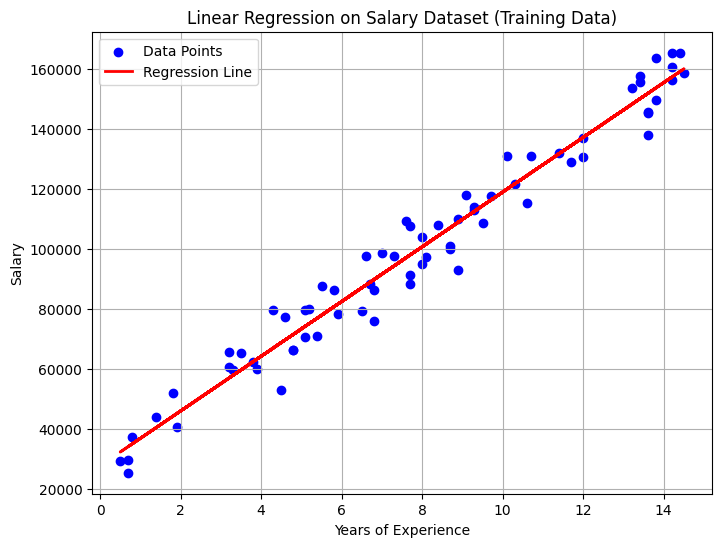

In [130]:
# figure for traing data
plt.figure(figsize=(8,6))
plt.scatter(x_train, y_train, color='blue', label='Data Points')
plt.plot(x_train, train_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Linear Regression on Salary Dataset (Training Data)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

**What this chart shows:** Each blue dot is one person from the training set. The dot's position across is their years of experience, and its height is their real salary. The red line is the model: for any amount of experience, the height of the line is the salary the model predicts.

**How to read it:** The vertical gap between a dot and the line is the model's error for that person (the residual). A dot right on the line means the model predicted that person's salary almost exactly. A dot far above the line means the person earns more than the model predicted, and a dot far below means they earn less.

**What I see:** The line runs through the middle of the dots, with roughly equal numbers above and below it, and the dots form a narrow band along the line. This matches the training R-squared of 0.965 from Step 13.

**What this chart does not prove:** The line was built from these exact people, so it is expected to fit them well. A good fit here does not yet show that the model works on new people. That is what the next chart is for.

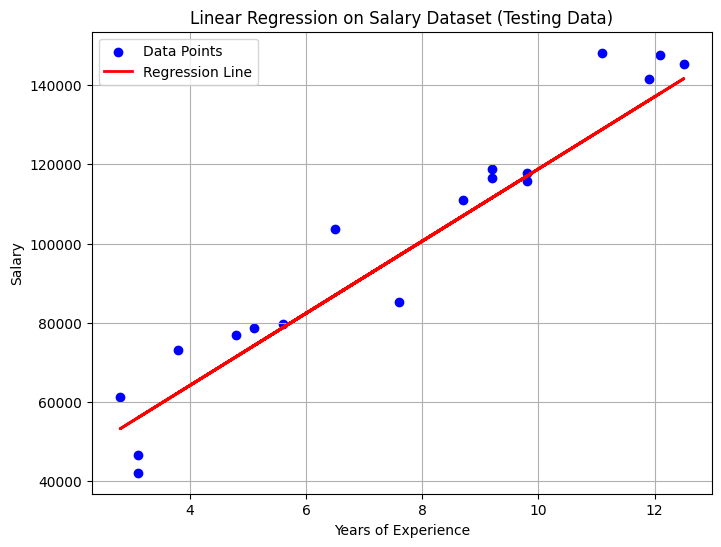

In [131]:
# figure for testing data
plt.figure(figsize=(8,6))
plt.scatter(x_test, y_test, color='blue', label='Data Points')
plt.plot(x_test, test_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Linear Regression on Salary Dataset (Testing Data)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

**What this chart shows:** Each blue dot is one person from the testing set. These 18 people were held back and never used to find the slope or the intercept. The red line is the same line as before, with the same slope and intercept learned from the training data.

**How to read it:** The vertical gap between a dot and the line is the model's error for that person (the residual). A dot right on the line means the model predicted that person's salary almost exactly. A dot far above the line means the person earns more than the model predicted, and a dot far below means they earn less.

**Why this chart matters:** This is the real exam. The model has never seen these people, so how close their dots are to the line shows how well it predicts for new people.

**What I see:** The dots stay close to the line and follow its upward direction. The spread around the line is a little wider than in the training chart, which matches the testing R-squared of 0.922 being a bit lower than the training R-squared of 0.965.

**Keep in mind:** There are only 18 test points, so a few unusual people can change how this chart looks. It gives a good picture, but the exact numbers are in Step 13.

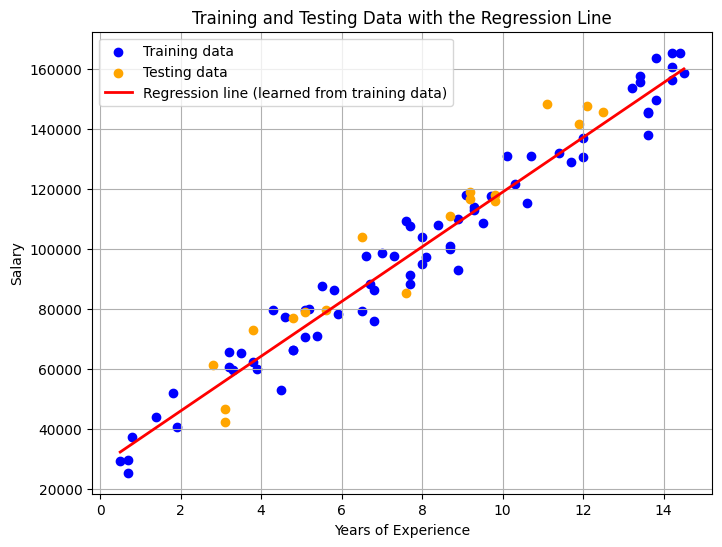

In [132]:
# Both sets on one chart, with one regression line
# The line only needs two points, the smallest and the largest x (YearsExperience), because a straight line is fixed by two points
line_x = np.array([x.min(), x.max()])
line_y = predict(line_x, m, b)

plt.figure(figsize=(8,6))
plt.scatter(x_train, y_train, color='blue', label='Training data')
plt.scatter(x_test, y_test, color='orange', label='Testing data')
plt.plot(line_x, line_y, color='red', linewidth=2, label='Regression line (learned from training data)')
plt.title('Training and Testing Data with the Regression Line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

**What this chart shows:** The (blue) dots are the training people and the (orange) dots are the testing people. Each dot is one real person: how far right it is shows their years of experience, and how high it is shows their real salary. The (red) line is the salary my model predicts for each number of years of experience using my own `predict` function

**How the line is drawn:** `line_x` holds the smallest and the largest years of experience in the data. `line_y` holds the salary my `predict` function gives for those two values. A straight line only needs two points, so the line is drawn between them.

**How to read it:** The red line is what the model predicted. A dot is what really happened. The gap between a dot and the line is the model's mistake for that person, which is the residual. A dot close to the line means a good prediction. A dot far from the line means a bad prediction.

**What I see:** Both the blue dots and the orange dots sit around the red line, with some above it and some below it. The blue dots are a bit closer to the line than the orange dots. This is expected, because the line was built from the blue dots and has never seen the orange ones.

**Conclusion:** The model also works on people it has never seen, because the orange dots stay near the line. They are only a little farther from it than the blue dots, which matches the test errors in Step 13.


---
# Step 13: Evaluate the model

The five metrics are worked out **twice**: once on the training set and once on the testing set, and then shown side by side in one table.

I do both on purpose, because they answer two different questions:

- **Training metrics** tell me how well the line fits the data it was built from.
- **Testing metrics** tell me how well it works on new data, which is the score that counts for real use.

**The comparison between them is the finding.** If training is very good and testing is much worse, the model has memorised the training data and does not generalise. If the two are close, the model has learned a pattern that holds up.

In [133]:
#Evaluation Metrics for Training and Testing Data

pd.options.display.float_format = '{:,.6f}'.format


results = pd.DataFrame({
    "Training": [
        mse(y_train, train_pred),
        mae(y_train, train_pred),
        rmse(y_train, train_pred),
        r2(y_train, train_pred),
        adjusted_r2(y_train, train_pred, 1)
    ],
    "Testing": [
        mse(y_test, test_pred),
        mae(y_test, test_pred),
        rmse(y_test, test_pred),
        r2(y_test, test_pred),
        adjusted_r2(y_test, test_pred, 1)
    ]
}, index=["MSE", "MAE", "RMSE", "R-squared", "Adjusted R-squared"])

print(results)

                            Training           Testing
MSE                47,572,717.610616 85,431,911.159711
MAE                     5,797.411009      7,670.629794
RMSE                    6,897.297848      9,242.938448
R-squared                   0.965170          0.922306
Adjusted R-squared          0.964658          0.917450


### Reading the results

| Metric | Training | Testing |
|---|---|---|
| MSE | about 47,572,718 | about 85,431,911 |
| MAE | about 5,797 | about 7,671 |
| RMSE | about 6,897 | about 9,243 |
| R-squared | 0.965 | 0.922 |
| Adjusted R-squared | 0.965 | 0.917 |

### What each metric tells us

- **MSE** squares every error and averages them. Squaring puts the answer in "salary squared", so these numbers are very large and hard to picture. We use it mainly as a step on the way to RMSE.
- **RMSE** is the square root of MSE. This brings it back to salary units. The test RMSE of about 9,243 means a typical prediction on new people is off by roughly 9,243.
- **MAE** is the average size of the misses, ignoring whether the model guessed too high or too low. The test MAE of about 7,671 means that on average, the model is off by about 7,671.
- **R-squared** compares the model with a lazy model that gives everyone the average salary. A value of 0.922 on the testing set means the model removes about 92% of the error that the lazy model would make.
- **Adjusted R-squared** is R-squared with a small penalty for the number of features. With a single feature it is almost the same as R-squared.

### Comparing training and testing

- **The model fits well.** An R-squared of 0.965 on training means the line explains about 96.5% of the variation in salary. On new data it still explains about 92.2%.
- **There is a gap, and it is a small one.** Test errors are somewhat bigger than training errors. This is normal, because the line was tuned to the training rows and has never seen the test rows. A gap of this size does not suggest serious overfitting.
- **Part of the gap is just chance.** The testing set has only 18 people, so each person makes up about 5% of the result. One unusual person can move the test score a lot. In our test set, a single person who was missed by about 19,300 makes up about a quarter of the whole test MSE. A different split would give somewhat different test numbers.
- **In salary terms,** the test RMSE of about 9,243 is roughly 9% of the average salary of about 100,000. On the training set, it is about 7%.
- **RMSE is a bit higher than MAE.** Both are in salary units. MAE treats every miss at its real size, while RMSE squares the misses first, so big misses count for more. RMSE is only a little higher here, which means the misses are fairly similar in size, with a few larger ones..

### What we can deduce

1. The model learned a real pattern, because it works well on people it has never seen (R-squared 0.922 on testing).
2. The model is not memorising the training rows, because the training and testing scores are close.
3. A typical prediction is off by roughly 7% to 9% of the average salary.
4. The test set is small, so these numbers are a good guide and not an exact measure.

---
# Step 14: Look at the residuals

A residual is the error for one row: actual minus predicted. The assumption checks in the next step are all based on residuals.

I build one small table for the training rows and one for the testing rows. Each shows the actual salary, the predicted salary, and the residual side by side. (They use two different names, `res_train` and `res_test`, so that one does not overwrite the other.)

In [134]:
# Check the assumptions

#Calculating residuals for traing data

res_train = pd.DataFrame(
    {"Actual_Salary": y_train,
     "Predicted_Salary": train_pred,
     "Residuals": residuals(y_train, train_pred)
     }
)

res_train.head(10)

,Actual_Salary,Predicted_Salary,Residuals
0,"112,772.000000","112,466.749141",305.250859
1,"29,736.000000","34,054.829632","-4,318.829632"
2,"88,338.000000","97,878.485047","-9,540.485047"
3,"137,836.000000","151,672.708896","-13,836.708896"
4,"78,385.000000","81,466.687940","-3,081.687940"
5,"107,681.000000","97,878.485047","9,802.514953"
6,"98,561.000000","91,496.119505","7,064.880495"
7,"79,539.000000","74,172.555893","5,366.444107"
8,"29,096.000000","32,231.296621","-3,135.296621"
9,"100,787.000000","106,996.150106","-6,209.150106"


In [135]:
#Calculating residuals for testing data

res_test = pd.DataFrame(
    {"Actual_Salary": y_test,
     "Predicted_Salary": test_pred,
     "Residuals": residuals(y_test, test_pred)
     }
)

res_test.head(10)

,Actual_Salary,Predicted_Salary,Residuals
0,"141,580.000000","136,172.678295","5,407.321705"
1,"72,981.000000","62,319.591316","10,661.408684"
2,"111,023.000000","106,996.150106","4,026.849894"
3,"42,108.000000","55,937.225774","-13,829.225774"
4,"148,198.000000","128,878.546248","19,319.453752"
5,"145,418.000000","141,643.277331","3,774.722669"
6,"79,709.000000","78,731.388422",977.611578
7,"116,618.000000","111,554.982635","5,063.017365"
8,"147,567.000000","137,996.211307","9,570.788693"
9,"61,110.000000","53,201.926257","7,908.073743"


Most of the first test residuals are positive, which means the model predicted a bit too low for those people. The next cell checks whether that holds across the whole test set.

In [136]:
pd.options.display.float_format = '{:,.8f}'.format

print("Average training residual:", residuals(y_train, train_pred).mean())
print("Average testing residual: ", residuals(y_test, test_pred).mean())

Average training residual: 1.948917218084846e-11
Average testing residual:  3633.8795984759076


The average **training** residual is about 0.00000000002 (the `e-11` means "move the decimal 11 places left"). That is guaranteed by the least squares method, so it is also a useful check that the code is right.

The average **testing** residual is about +3,600. A positive residual means the real salary was higher than the model's prediction, so on these 18 people the model guessed slightly too low on average. The test people were not used to build the line, so their errors do not have to balance. With only 18 rows, this could easily be chance and not a real bias.

---
# Step 15: Check the assumptions

Linear regression is built on a few standards. When they hold, we can trust the line and its predictions. When they do not, the results can mislead us, even if the numbers look good.

Linearity can be looked at before building the model, because it only needs the raw data. The other checks use the model's errors (the residuals), so they come after the model is built.

| # | Assumption | In simple words | How I check it |
|---|---|---|---|
| 1 | **Linearity** | The data follows a straight line | Correlation and a scatter plot |
| 2 | **Independence of errors** | One person's error does not push the next person's error | Residuals plotted in row order |
| 3 | **Normality of errors** | Most errors are small, with a few big ones, evenly on both sides | Histogram of the residuals |
| 4 | **Constant variance** | The model's errors are about the same size for everyone | Residuals plotted against experience |
| 5 | **No multicollinearity** | Features are not too related to each other | Not applicable, one feature |

The checks use the **training** data because they are about how the fitted model's errors behave. The training residuals describe the model on the data it learned from, so that is where I check the assumptions. The testing set is kept for judging performance on new people (Step 13).

### Assumption 1: Linearity

**What it means:** When experience goes up, salary goes up by a steady amount, so the points follow a straight line and not a curve.

**The number:** The correlation tells us how close the points are to a straight line. A value near +1 means a strong upward straight line, near -1 a strong downward straight line, and near 0 means no straight line at all.

In [137]:
correlation(x_train, y_train)

np.float64(0.9824306944743619)

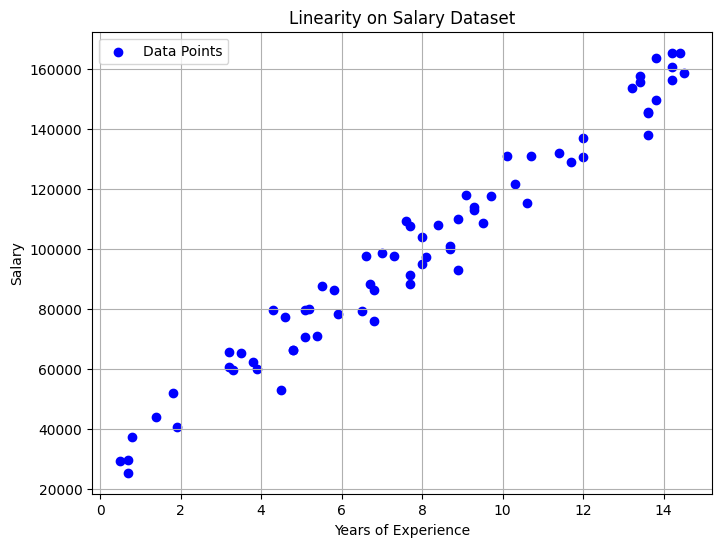

In [138]:
# Linearity for training data
plt.figure(figsize=(8,6))
plt.scatter(x_train, y_train, color='blue', label='Data Points')

plt.title('Linearity on Salary Dataset')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

**What we expect to see if it holds:** The dots form a narrow band that rises in a straight line.

**What would be a problem:** The dots bend into a curve, or spread out as a cloud with no direction.

**What I see:** The correlation is about 0.98, which is very close to 1, and the dots form a straight rising band with no bend.

**Verdict: holds.** Linear Regression is a good choice for this data.

### Assumption 2: Independence of errors

**What it means:** An error is how far the model's guess is from the real salary. Independent means that one person's error should not push the next person's error up or down. If the model guessed too high for one person, that should not make it guess too high for the next.

**What we expect to see if it holds:** Dots jumping randomly above and below the red zero line, with no pattern.

**What would be a problem:** A wave, a steady climb or fall, or long runs of dots all above the line and then all below it.

**What I see:** The dots are scattered randomly above and below zero, with no wave or trend.



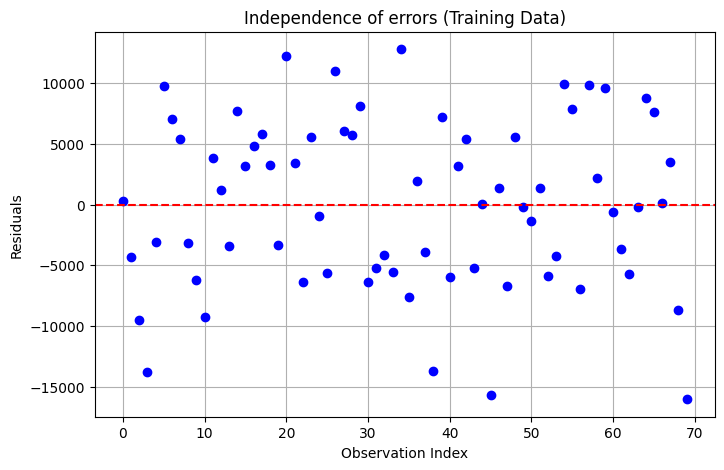

In [139]:
# Independence of errors

train_residuals = residuals(y_train, train_pred)

plt.figure(figsize=(8,5))
plt.plot(train_residuals, marker='o', linestyle='', color='blue')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Independence of errors (Training Data)')
plt.xlabel('Observation Index')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

**Verdict: no pattern seen, but the check is limited here.** This check matters most when data comes in time order, like monthly sales, where one month's error can carry into the next. My rows are shuffled and have no time order, so I can say there is no pattern, but I cannot claim to have fully tested independence.


### Assumption 3: Normality of errors

**What it means:** The errors should follow a bell shape. If the errors are normal, the histogram of the residuals should look like a bell: tall in the middle and thin at both ends.

**How to read the histogram:** The bottom shows the size of the error. Negative means the model guessed too high, and positive means it guessed too low. The height of each bar is how many people had an error of that size.

**What we expect to see if it holds:** Tall bars around zero that get shorter on both sides, like a hill.

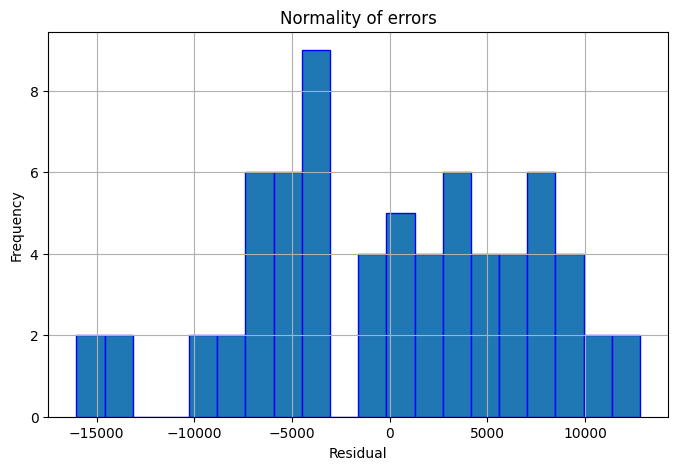

In [140]:
# INormality of errors

train_residuals = residuals(y_train, train_pred)

plt.figure(figsize=(8,5))
plt.hist(train_residuals, bins = 20,edgecolor = 'blue')
plt.title('Normality of errors')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

**What would be a problem:** The hill leans heavily to one side, a few bars sit very far away from the rest (extreme outliers), or there are two separate hills.

**What I see:** The errors are centred around zero and spread out on both sides, with no extreme outliers and no strong lean to one side. The shape is lumpy and fairly flat on top, not a perfect bell. That is normal, because with only 70 values a histogram is rarely smooth.

**Verdict: roughly holds.** It is not a perfect bell, but there is no sign of a serious problem.

### Assumption 4: Constant variance

**What it means:** The model's errors should be about the same size for everyone, whether they have 1 year or 14 years of experience. "Equal spread" means the dots sit at about the same distance from the zero line on the left, in the middle and on the right of the chart. Think of a fare model that is accurate for short trips but wildly off for long trips. Its spread would not be constant.

#### **I check it in two ways:**

1. **A chart:**

**How to read the chart:** The bottom is years of experience and the height is the error. The red line at zero means no error.

**What we expect to see if it holds:** An even horizontal band of dots around the zero line, with the same thickness from left to right.

2. **A number:** split the training rows at the median experience, and compare the spread (standard deviation) of the residuals in the low half and in the high half. If one is more than about twice the other, that is a warning.

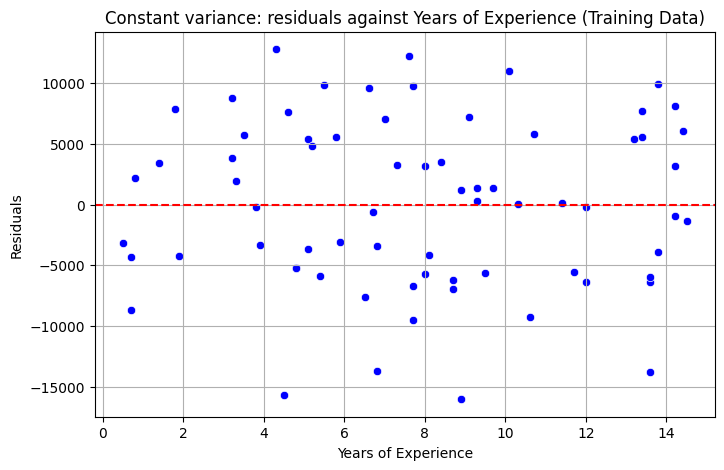

In [141]:
# Constant variance: residuals against x
plt.figure(figsize=(8,5))
sns.scatterplot(x=x_train, y=train_residuals, color='blue')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Constant variance: residuals against Years of Experience (Training Data)')
plt.xlabel('Years of Experience')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

In [142]:
# Constant variance: compare the spread of the low half and the high half
middle = np.median(x_train)

low_half = train_residuals[x_train <= middle]    # residuals of people at or below the median experience
high_half = train_residuals[x_train > middle]    # residuals of people above the median experience

print("Median experience:", middle)
print(f"Rows in low half: {len(low_half)} spread: {round(low_half.std(), 3)}")
print(f"Rows in high half: {len(high_half)} spread: {round(high_half.std(), 3)}")
print(f"Ratio (bigger / smaller): {round(max(low_half.std(), high_half.std()) / min(low_half.std(), high_half.std()), 2)}")

Median experience: 7.7
Rows in low half: 36 spread: 7237.107
Rows in high half: 34 spread: 6479.624
Ratio (bigger / smaller): 1.12


**Verdict: holds.** The chart shows an even band with no funnel shape, and the two halves have similar spreads (about 7,200 for the low half and about 6,500 for the high half, a ratio of about 1.1, far below the warning level of 2).

*How the split works:* `train_residuals[x_train <= middle]` picks only the residuals for rows where the experience is at or below the median. It is the same True and False selection idea used earlier with `np.isnan`.

### Assumption 5: No multicollinearity

Multicollinearity means that two or more **features** are strongly related to each other. This model has only one feature (YearsExperience), so there is nothing to be related to. This assumption **does not apply** here. It becomes important in multiple linear regression.

### Summary of the assumption checks

| Assumption | Result |
|---|---|
| Linearity | Holds (correlation about 0.98) |
| Independence of errors | No pattern seen, but not properly testable here because the rows have no time order |
| Normality of errors | Roughly holds (not a perfect bell, no serious problem) |
| Constant variance | Holds (spread ratio about 1.1) |
| No multicollinearity | Not applicable (one feature) |

These are the standards linear regression is built on. The ones that can be checked are met or roughly met, so linear regression is a reasonable choice for this data and its results can be trusted.

One caution: this dataset is synthetic, made from a straight line plus random noise, so it is not surprising that the checks pass. Real-world data is messier, and the same checks might show problems.

---
# Step 16: The story, what I found

**The question.** Can a straight line predict a person's salary from their years of experience, and can I build that line using only basic maths and NumPy?

**What I did.**

1. Loaded a messy dataset of 100 people, with 12 missing values.
2. Looked at it, found the 6 + 6 blanks, and cleaned it. My first approach (filling blanks with the mean) hurt the model. Tracking down why led me to drop the incomplete rows, which left 88.
3. Split the data by hand into 70 training rows and 18 testing rows, and checked that the test range sat inside the training range.
4. Wrote the maths as plain functions, and proved they were right by checking them against known answers.
5. Learned the line from the training data only.
6. Used the line to predict on both sets, and compared the results.
7. Checked the assumptions behind linear regression.

**What I found.**

- The model is: salary is about **27,672 + 9,118 x years of experience**. In plain words, each extra year of experience goes with about 9,118 more in salary, and a person with zero years is predicted to earn about 27,672.
- On the training people, the model is typically off by about 6,900 (RMSE), which is about 7% of the average salary. It explains about 96.5% of the variation in salary (R-squared 0.965).
- On the testing people, whom the model had never seen, it is typically off by about 9,200 (RMSE), which is about 9% of the average salary. It explains about 92.2% of the variation (R-squared 0.922).
- The results on the two groups are close. A small gap is expected, because the line was built from the training people. The model learned a real pattern instead of memorising rows.
- The assumptions that can be checked hold, or roughly hold, so linear regression is a reasonable choice for this data.
- It fits the training data very well (R-squared 0.965) and holds up on new data (R-squared 0.922, typical error about 9,200).
- The training and testing results are close, with a modest gap. That is the sign of a model that learned a real pattern instead of memorising rows.
- The assumptions that can be checked held up.

 ## My biggest lesson

The metrics gave me a warning, and I only understood it by looking at the individual errors. When I filled blanks with the mean, the test score dropped a lot. Instead of blaming the model, I looked for the one biggest error, and it came from a row with an invented value. A single made-up row caused more than half of the test error. Always look at where the largest errors come from. Do not trust a score without asking why.

## How to be careful with these results

- **The data is synthetic.** It was made up, so these results show that the method works. They say nothing about real salaries.
- **This shows a pattern, not a cause.** In this data, more experience goes with higher pay. It does not prove that experience is the only reason.
- **Stay inside the range.** The line is only reliable between about 0.5 and 14.5 years. Predicting for 30 years would be a guess.
- **The test set is small.** With 18 people, one unusual person can move the score a lot, so the test numbers are a good guide, not an exact measure.
- **Twelve rows were dropped.** If those people were different from the rest in some way, that could affect the results.


## Questions I asked while building this

**Should I evaluate on the training set, the testing set, or both?**
Both, because they answer different questions. The training metrics show how well the line fits the data it learned from. The testing metrics show how it performs on new data. The gap between the two is the diagnosis: a big gap means overfitting, a small gap means the model generalises.

**Why do most of the charts and checks use the training data and not the testing data?**
Because the line was **learned from** the training data. The training charts show how well the line represents what it was built from. The assumption checks are about how the fitted model's errors behave, so they use the training residuals. The testing set has one job: to give an honest score on rows the model has never seen. It is deliberately kept away from learning and from tuning, so it stays a fair exam. That is also why I added the chart in Step 12 that shows both sets together, so the test points can be judged against the same line.

**What would have happened if I had kept the mean-filled rows?**
The test score would have looked much worse than the model deserved (R-squared 0.774 instead of 0.922), because a few invented points would have dominated the error. Checking the biggest residual, and not just trusting the metrics, is what exposed it.

---
# Step 17: What I would do next

This is my improvement list for when I come back to this project. For each item I wrote what it is, why it matters and how I would do it.

## Improve what I built

**1. Split first, then clean.**
- *What:* In this notebook I cleaned the whole table and then split it.
- *Why it matters:* If I fill a missing value with an average, and that average is worked out using the test rows, then information from the test set leaks into the training set. The test is no longer a fair exam. This is called data leakage.
- *How:* Split the rows first. Work out any averages from the **training** rows only. Use those same averages to fill blanks in both the training and the testing set. Because I dropped rows instead of filling them, this did not affect my results, but it is the habit to build.

**2. Use a bigger test set, and test more than once.**
- *What:* My test set has only 18 people, so one unusual person can move the score a lot.
- *Why it matters:* A score from 18 people is not very stable.
- *How:* Use a larger dataset, with a few hundred rows or more. I can also repeat the test several times by hand: cut the data into 5 equal parts by slicing, use each part as the test set once, train on the other four, and compare the 5 scores. If the scores are close to each other, I can trust the model more. (This idea is called k-fold cross-validation.)

**3. Compare different ways of handling missing values.**
- *What:* I compared mean fill with dropping rows, but I did it by accident, after something went wrong.
- *How:* Run the full pipeline for each method (drop rows, fill with the mean, fill with the median), keep the same test rows, and put the test RMSE and R-squared of each in one table. This shows which choice is best in a proper way.

**4. Study the biggest errors.**
- *How:* After predicting, sort the residuals by size and look at the five biggest. Ask whether they come from invented values, from unusual people, or from something the model is missing. This is what found my mean-fill problem.

**5. Check the assumptions on the testing data too.**
- *How:* Repeat the residual charts with the testing residuals and see whether the same patterns appear. With only 18 points the charts will be rough, so a bigger test set (item 2) comes first.

## Build on it

**6. Build the same model with gradient descent.**
- *What:* Right now I find the slope and intercept using sum formulas, which give the answer in one step. Gradient descent finds them by starting with a guess and improving it many times.
- *Why it matters:* It is the method behind most machine learning, so understanding it on this simple model prepares me for harder ones.
- *How:* Start with `m = 0` and `b = 0`, predict, work out the error, adjust `m` and `b` a small step to reduce the error, and repeat. At the end, my gradient descent answer should be very close to my formula answer (about 9,118 and 27,672). Plot the error going down as the loop repeats.

**7. Multiple linear regression.**
- *What:* This notebook is simple linear regression, with one feature. Multiple linear regression uses more than one feature, for example years of experience and level of education.
- *What changes:* The sum formulas no longer work, so it needs matrix maths. Adjusted R-squared becomes much more useful, and the multicollinearity assumption now applies and has to be checked.

**8. Regularisation.**
- *What:* Ridge, Lasso and Elastic Net.
- *Why it matters:* They protect a model from overfitting, especially when there are many features.

**9. Wrap the functions in a class.**
- *What:* Once I have learned classes and objects, I can put `fit`, `predict` and the metrics together in one class.
- *Why it matters:* The maths stays exactly the same. The class only organises the code, which is how libraries are built.


## Take it to the real world

**11. Apply the method to a real problem from Ghana or Africa.**
- *Ideas:* house prices in Accra against size or location, cocoa yield against rainfall, fuel prices against transport fares, electricity use against temperature or time.
- *What to do differently with real data:* Write down where the data comes from and what each column means. Expect more missing values and more unusual rows. Check the assumptions carefully, because real data is messier than my synthetic data and the checks are more likely to show problems. Explain the results in plain words that someone who works in that area can use.

**12. Turn it into something people can use.**
- *Later, when I learn deployment:* Put the trained model behind a simple app that takes a number and returns a prediction, which is a first step towards a full system.

---

*Built by Benedicta Bondzie, The Tech Diva. Find me on [LinkedIn](https://www.linkedin.com/in/benedicta-bondzie-the-tech-diva/).*

---
# Final check: comparing with scikit-learn

Everything in this notebook was built from scratch. As a last proof, I ran scikit-learn's `LinearRegression` on the **same training and testing rows** and compared its answers with mine.

The library is used here **only to check my work**. It never produced any of my results. If my slope, intercept, predictions and metrics match the library's, it shows that my formulas and functions are correct.

In [143]:
from sklearn.linear_model import LinearRegression

# scikit-learn needs x and y as tables with one column, so reshape(-1, 1)
x_train_2d = x_train.reshape(-1, 1)
y_train_2d = y_train.reshape(-1, 1)
x_test_2d = x_test.reshape(-1, 1)

# Creating and training the library model
model = LinearRegression()
model.fit(x_train_2d, y_train_2d)

# Predicting on the testing data
lib_pred = model.predict(x_test_2d)

# Slope and intercept from the library (named differently so they do not overwrite my m and b)
lib_slope = model.coef_[0][0]
lib_intercept = model.intercept_[0]

print("My slope:          ", m)
print("Library slope:     ", lib_slope)
print()
print("My intercept:      ", b)
print("Library intercept: ", lib_intercept)
print()
print("My first 5 test predictions:     ", test_pred[:5])
print("Library first 5 test predictions:", lib_pred[:5].flatten())

My slope:           9117.665059179164
Library slope:      9117.665059179151

My intercept:       27672.46409098011
Library intercept:  27672.46409098021

My first 5 test predictions:      [136172.67829521  62319.59131586 106996.15010584  55937.22577444
 128878.54624787]
Library first 5 test predictions: [136172.67829521  62319.59131586 106996.15010584  55937.22577444
 128878.54624787]


**Result:** My slope and intercept match the library’s to about 10 decimal places, and the first five test predictions are identical. The tiny differences far out in the decimals come from computer rounding. This confirms that my from-scratch implementation is correct.